In [119]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/teejmahal20/airline-passenger-satisfaction/test.csv
/kaggle/input/datasets/teejmahal20/airline-passenger-satisfaction/train.csv


# Loading Data

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [121]:
TRAIN_PATH = '/kaggle/input/datasets/teejmahal20/airline-passenger-satisfaction/train.csv'
TEST_PATH = '/kaggle/input/datasets/teejmahal20/airline-passenger-satisfaction/test.csv'

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print('Train shape: ', train.shape)
print('Test shape: ', test.shape)

Train shape:  (103904, 25)
Test shape:  (25976, 25)


In [122]:
train.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [123]:
test.head(3)

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,3,4,3,4,3,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,3,1,5,4,5,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,2,4,2,2,2,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied


In [124]:
train = train.drop(columns=['Unnamed: 0', 'id'])
test =  test.drop(columns=['Unnamed: 0', 'id'])

In [125]:
pd.set_option('display.max_columns', None)
train.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [126]:
train.describe(include='number').round(2)

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103904.00,103594.00
mean,39.38,1189.45,2.73,3.06,2.76,2.98,3.20,3.25,3.44,3.36,3.38,3.35,3.63,3.30,3.64,3.29,14.82,15.18
std,15.11,997.15,1.33,1.53,1.40,1.28,1.33,1.35,1.32,1.33,1.29,1.32,1.18,1.27,1.18,1.31,38.23,38.70
min,7.00,31.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,27.00,414.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,3.00,3.00,3.00,2.00,0.00,0.00
50%,40.00,843.00,3.00,3.00,3.00,3.00,3.00,3.00,4.00,4.00,4.00,4.00,4.00,3.00,4.00,3.00,0.00,0.00
75%,51.00,1743.00,4.00,4.00,4.00,4.00,4.00,4.00,5.00,4.00,4.00,4.00,5.00,4.00,5.00,4.00,12.00,13.00
max,85.00,4983.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,1592.00,1584.00


# Data Cleaning

In [127]:
data_types = pd.DataFrame({
    'Variable': train.columns
}, index=train.dtypes)
data_types

,Variable
object,Gender
object,Customer Type
int64,Age
object,Type of Travel
object,Class
int64,Flight Distance
int64,Inflight wifi service
int64,Departure/Arrival time convenient
int64,Ease of Online booking
int64,Gate location


In [128]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding                    1039

In [129]:
train.isna().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction                           0
dtype: int64

In [130]:
train['Arrival Delay in Minutes'].mean()

np.float64(15.178678301832152)

In [131]:
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(train['Arrival Delay in Minutes'].mean())
test['Arrival Delay in Minutes'] = test['Arrival Delay in Minutes'].fillna(test['Arrival Delay in Minutes'].mean())

In [132]:
train.isna().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [133]:
test.isna().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

# Charts

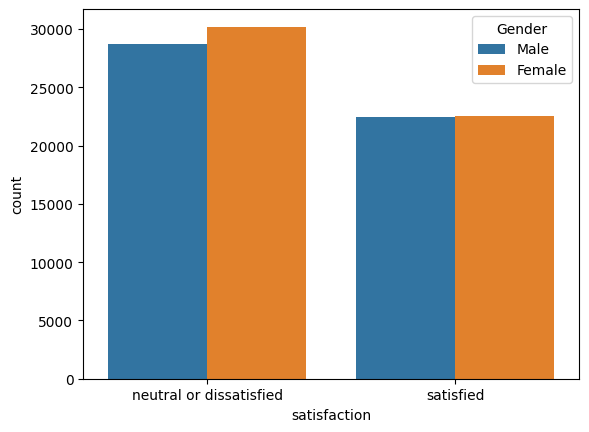

In [134]:
sns.countplot(data=train, x='satisfaction', hue='Gender')
plt.show()

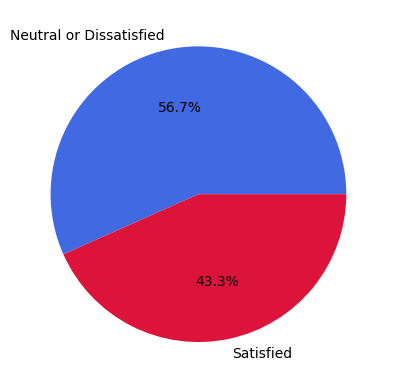

In [135]:
plt.pie(
    train['satisfaction'].value_counts(),
    labels=['Neutral or Dissatisfied', 'Satisfied'],
    autopct='%1.1f%%',
    colors=['royalblue', 'crimson']
)
plt.show()

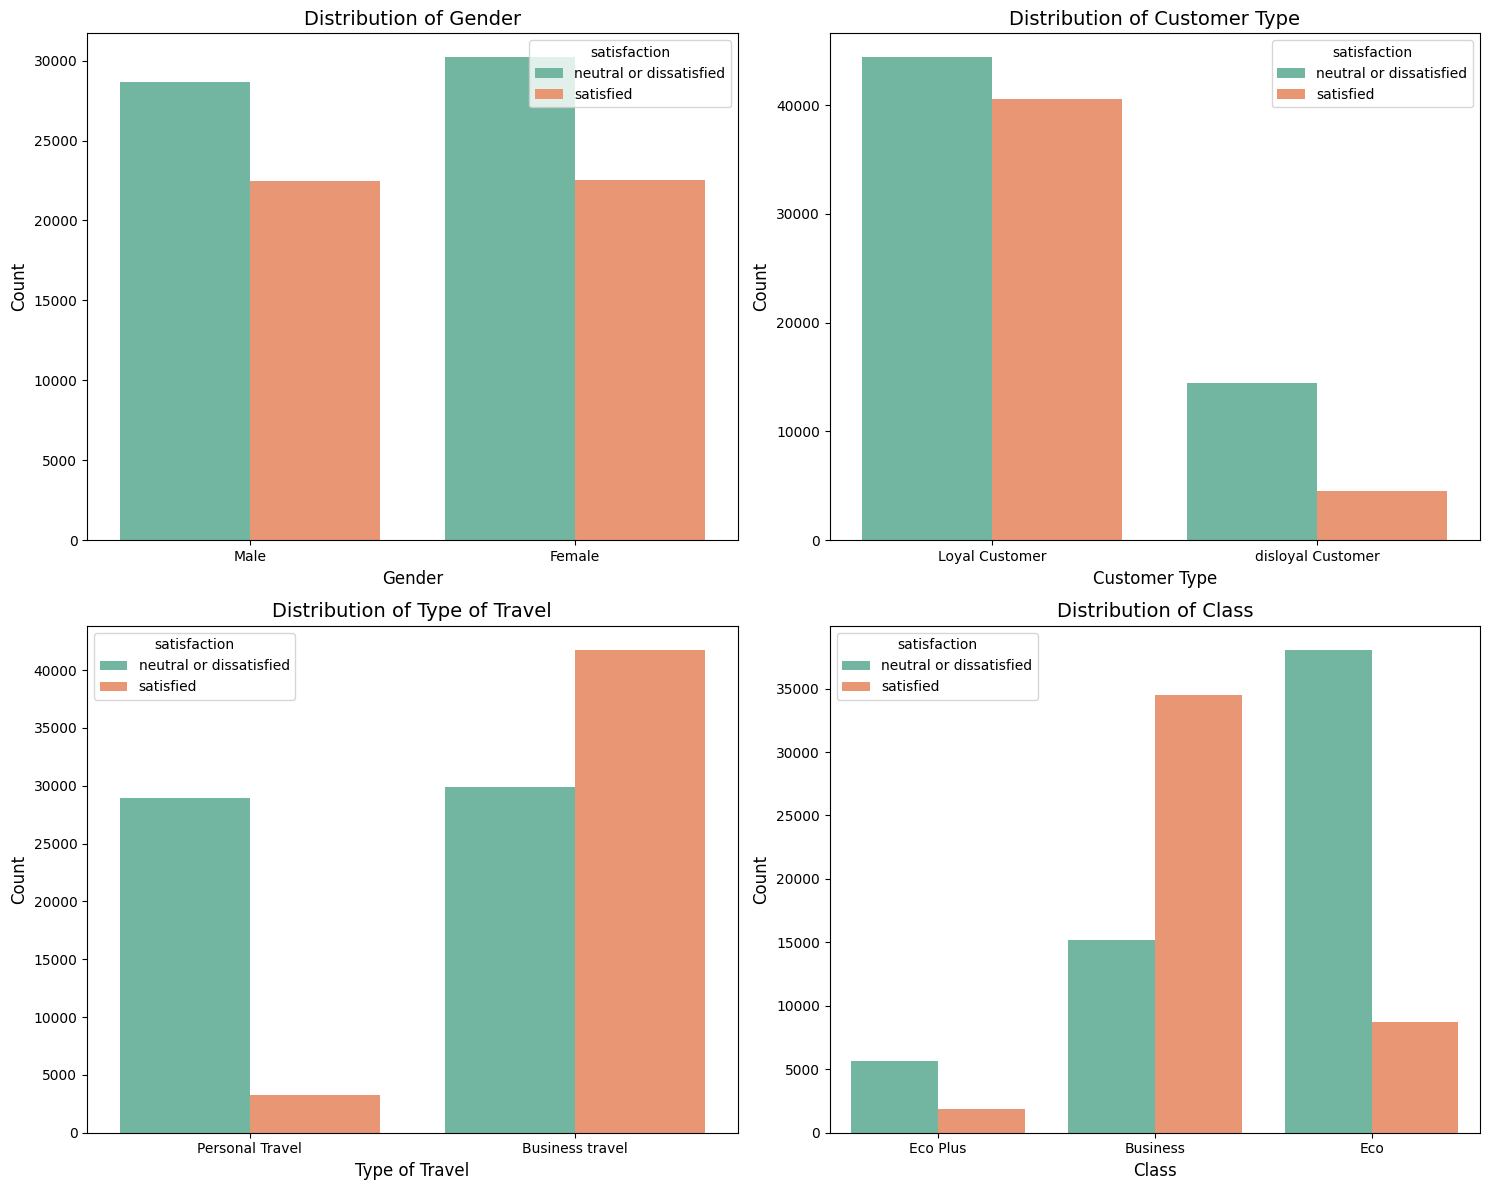

In [136]:
cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
plt.figure(figsize=(15, 12))
for i, col in enumerate(cols):
    plt.subplot(2, 2, i+1)
    sns.countplot(data=train, x=col, hue='satisfaction', palette='Set2')
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

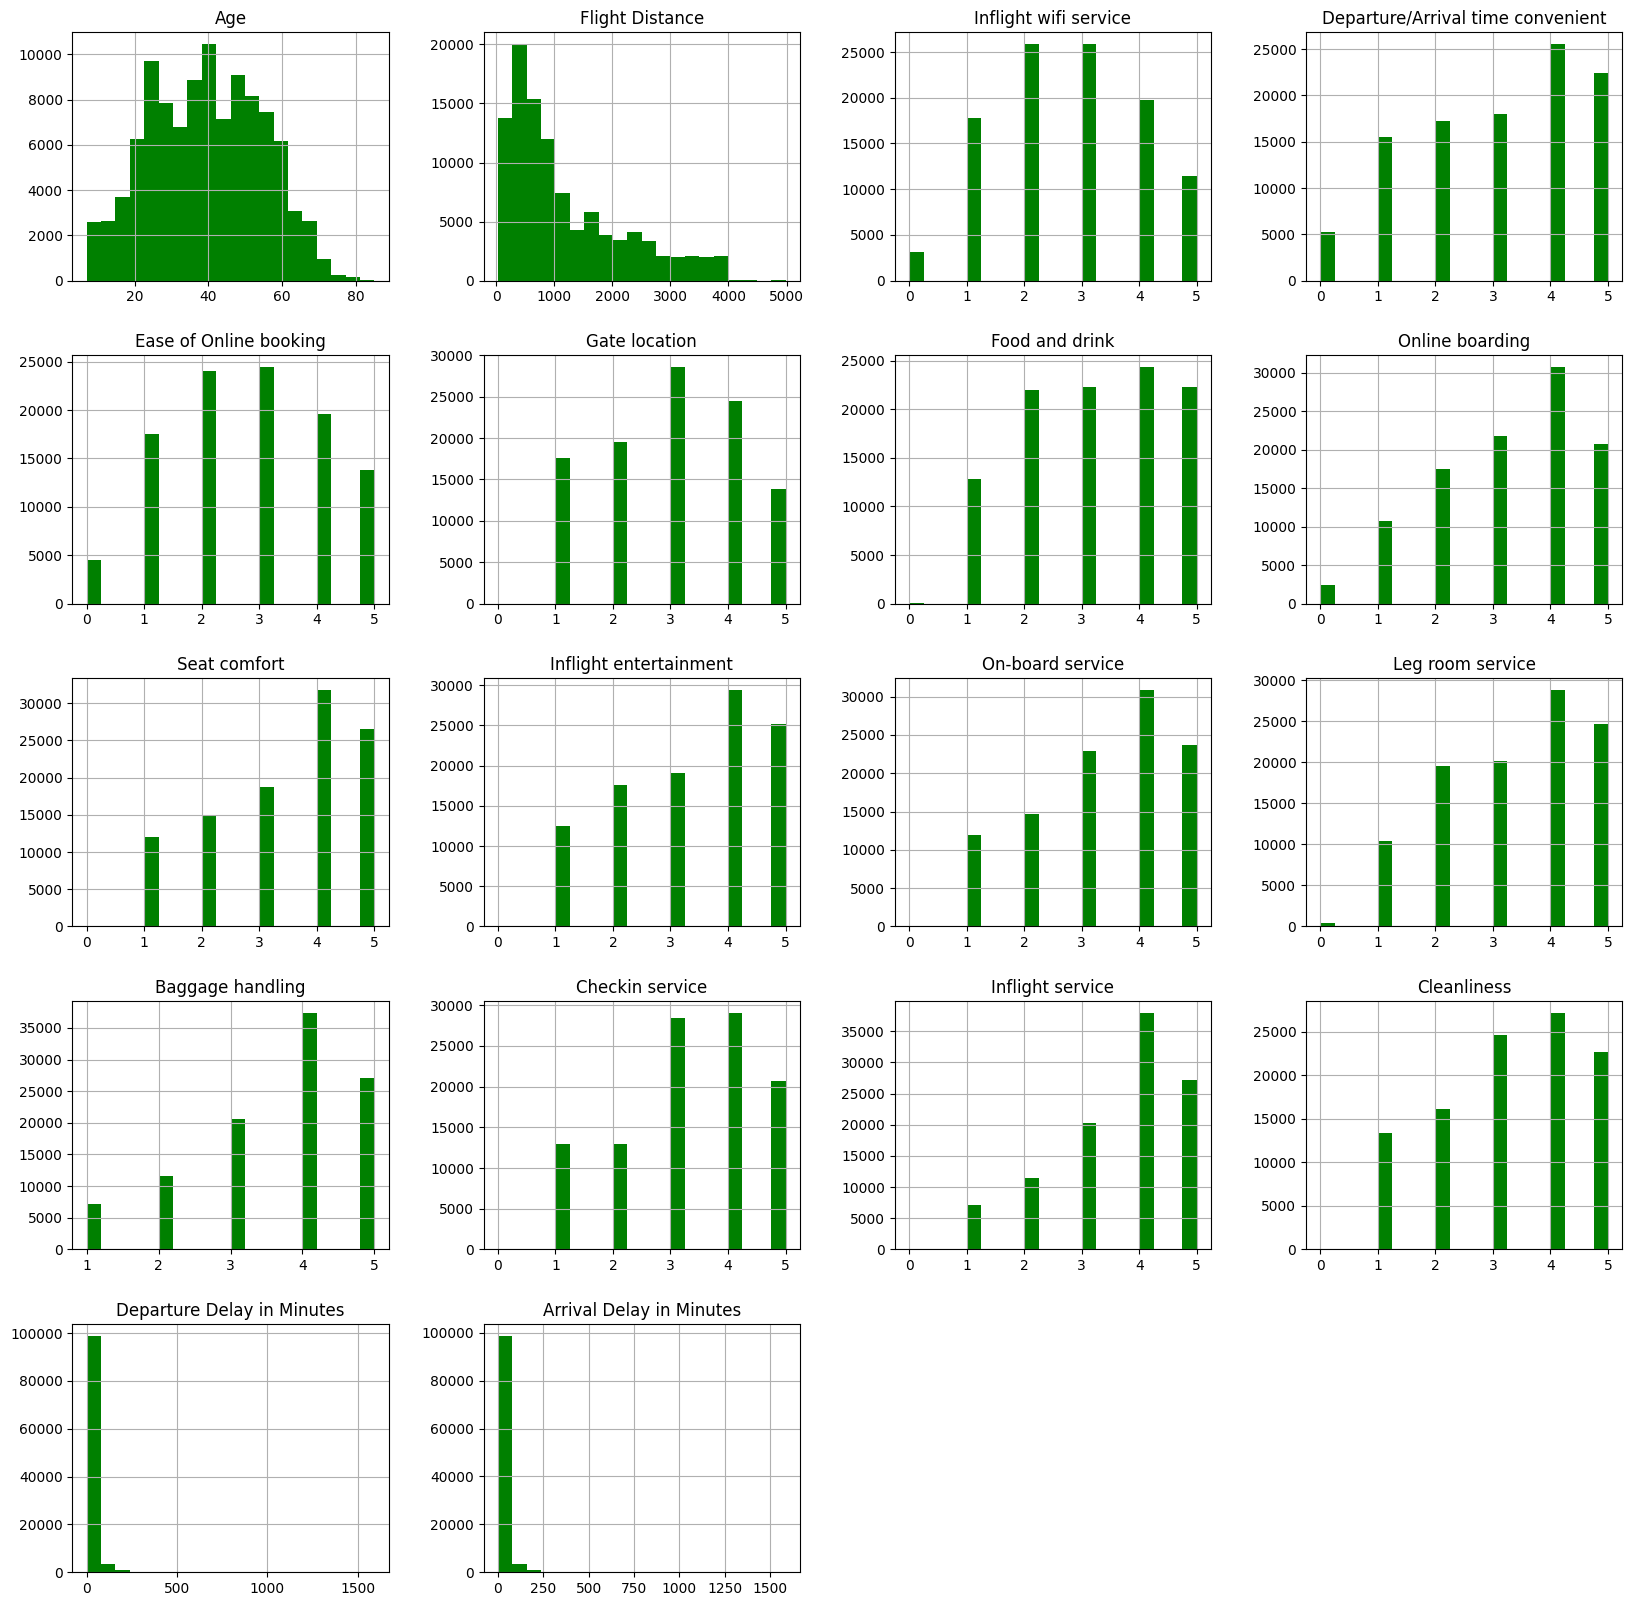

In [137]:
train.hist(bins=20, figsize=(20, 20), color='green')
plt.show()

# Column Data Encoding

In [138]:
obj_types = train.select_dtypes(include='object').columns
for col in obj_types:
    print(f'{col}: {train[col].unique()}')

Gender: ['Male' 'Female']
Customer Type: ['Loyal Customer' 'disloyal Customer']
Type of Travel: ['Personal Travel' 'Business travel']
Class: ['Eco Plus' 'Business' 'Eco']
satisfaction: ['neutral or dissatisfied' 'satisfied']


In [139]:
encoder=LabelEncoder()
columns = train.select_dtypes(include='object').drop(columns='satisfaction').columns
test_columns = test.select_dtypes(include='object').drop(columns='satisfaction').columns
for col in columns:
    train[col] = encoder.fit_transform(train[col])
for test_col in test_columns:
    test[test_col] = encoder.fit_transform(test[test_col])
train.head()


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,1,0,13,1,2,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,1,25,0,0,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,0,0,26,0,0,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,0,0,25,0,0,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,1,0,61,0,0,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [140]:
test.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,0,52,0,1,160,5,4,3,4,3,4,3,5,5,5,5,2,5,5,50,44.0,satisfied
1,0,0,36,0,0,2863,1,1,3,1,5,4,5,4,4,4,4,3,4,5,0,0.0,satisfied
2,1,1,20,0,1,192,2,0,2,4,2,2,2,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,1,0,44,0,0,3377,0,0,0,2,3,4,4,1,1,1,1,3,1,4,0,6.0,satisfied
4,0,0,49,0,1,1182,2,3,4,3,4,1,2,2,2,2,2,4,2,4,0,20.0,satisfied


# Additional Charts

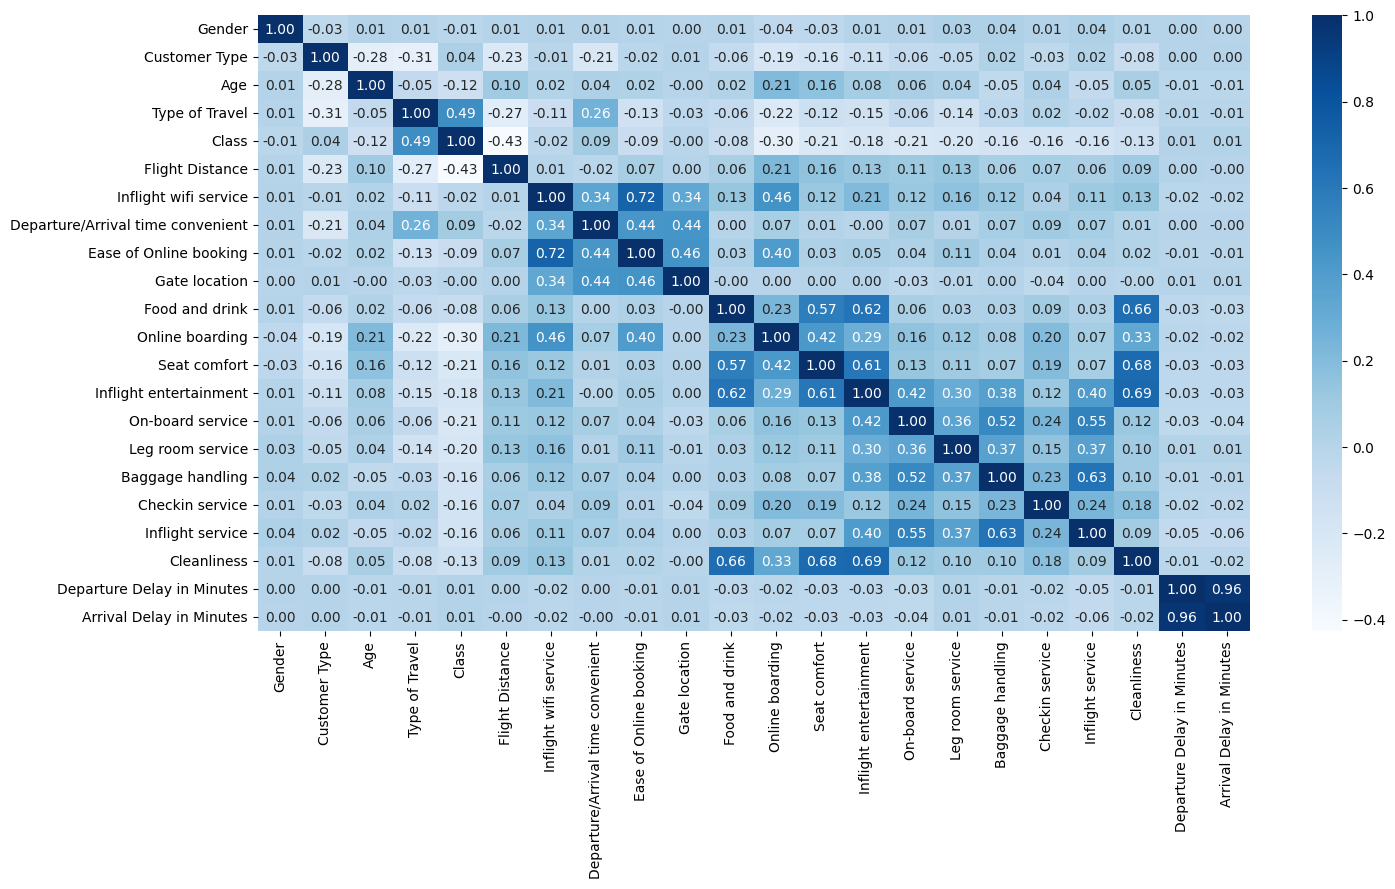

In [141]:
plt.figure(figsize=(16, 8))
sns.heatmap(train.drop(columns='satisfaction').corr(), annot=True, fmt='.2f', cmap='Blues')
plt.show()

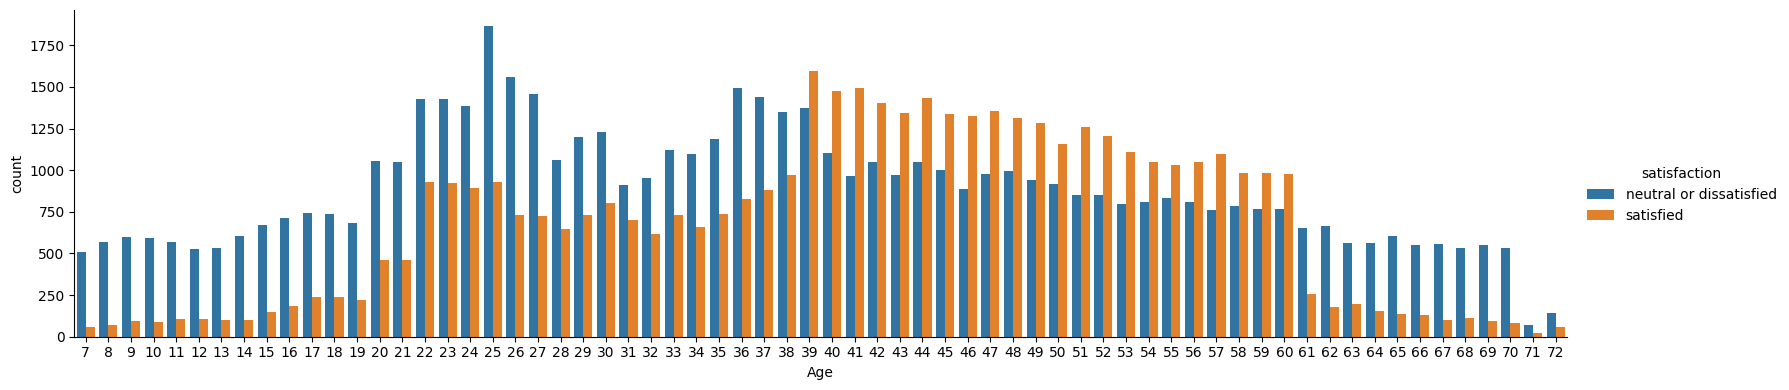

In [142]:
sns.catplot(
    data=train,
    x='Age',
    height=4,
    aspect=4,
    kind='count',
    hue='satisfaction',
    order=range(7, 73)
)
plt.show()

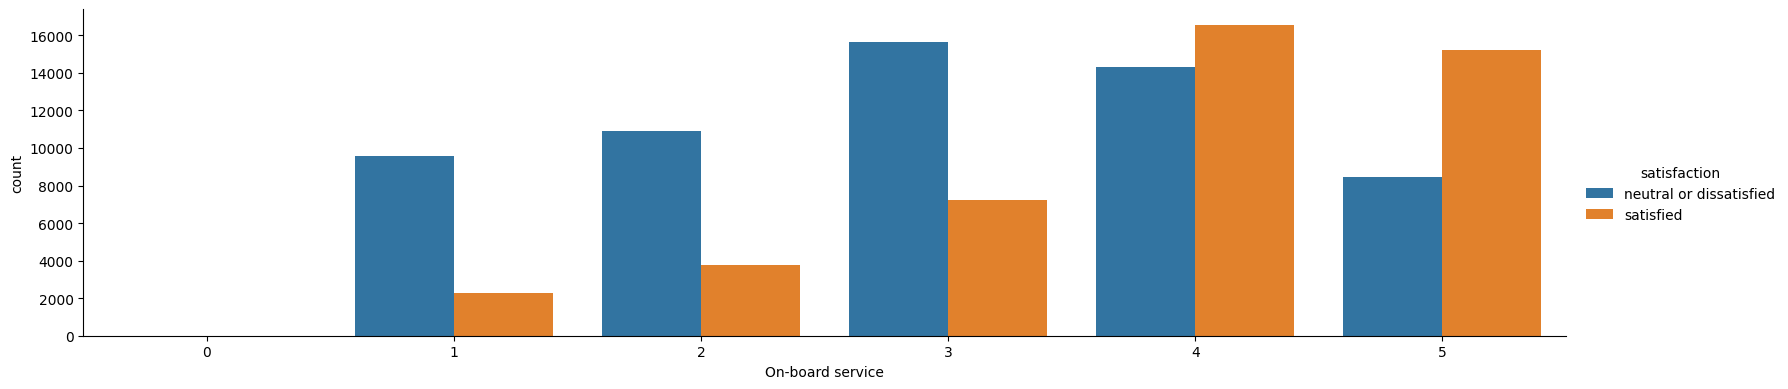

In [143]:
sns.catplot(
    data=train,
    x='On-board service',
    height=4,
    aspect=4,
    kind='count',
    hue='satisfaction'
)
plt.show()

## Filtering Data

In [144]:
train[['Gender', 'Age', 'Type of Travel']].head()

,Gender,Age,Type of Travel
0,1,13,1
1,1,25,0
2,0,26,0
3,0,25,0
4,1,61,0


In [145]:
train.loc[2: 5, ['Gender', 'Age', 'Flight Distance']]

,Gender,Age,Flight Distance
2,0,26,1142
3,0,25,562
4,1,61,214
5,0,26,1180


In [146]:
train.loc[train['Age'] > 50, ['Gender', 'Age', 'Flight Distance']].head()

,Gender,Age,Flight Distance
4,1,61,214
7,0,52,2035
12,1,53,834
23,0,58,2139
25,1,57,719


In [147]:
train.loc[train['Gender'] == 1, ['Gender', 'Age', 'Flight Distance']].head()

,Gender,Age,Flight Distance
0,1,13,460
1,1,25,235
4,1,61,214
6,1,47,1276
9,1,20,1061


# Models

In [148]:
X_train = train.drop(columns='satisfaction')
y_train = train['satisfaction']

X_test = test.drop(columns='satisfaction')
y_test = test['satisfaction']

## Decision Tree

In [149]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42, max_depth=10)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [150]:
from sklearn.metrics import accuracy_score, f1_score

preds = model.predict(X_test)
score = accuracy_score(y_test, preds)
score

0.9459886048660302

## Random Forest

In [151]:
from sklearn.ensemble import RandomForestClassifier

model2 = RandomForestClassifier(
    random_state=42,
    n_estimators=200,
    max_depth=None,)
model2.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [152]:
forestpreds = model2.predict(X_test)
forestscore = accuracy_score(y_test, forestpreds)
forestscore

0.9630813058207576

## KNeighborsClassifier

In [153]:
from sklearn.neighbors import KNeighborsClassifier

model3 = KNeighborsClassifier(n_jobs=-1, n_neighbors=10)
model3.fit(X_train, y_train)

KNeighborsClassifier(n_jobs=-1, n_neighbors=10)

In [154]:
knpreds = model3.predict(X_test)
knscore = accuracy_score(y_test, knpreds)
knscore

0.7458038189097629

## Logistic Regression

In [155]:
from sklearn.linear_model import LogisticRegression

linearmodel = LogisticRegression(max_iter=10000, random_state=42)
linearmodel.fit(X_train, y_train)
linearpreds = linearmodel.predict(X_test)
linearscore = accuracy_score(y_test, linearpreds)
linearscore

0.8709578072066523

# Total Models

In [158]:
models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42),
    'Random Forest': RandomForestClassifier(
        n_jobs=-1,
        random_state=42,
        n_estimators=200,
        max_depth=None,),
    'KNN' : KNeighborsClassifier(
        n_jobs=-1,
        n_neighbors=10),
    'LogisticRegression': LogisticRegression(
        max_iter=10000,
        random_state=42)
}

results = []
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label='neutral or dissatisfied', zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "F1": round(f1, 4),
    })
df_result = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
df_result

,Model,Accuracy,F1
1,Random Forest,0.9631,0.9675
0,Decision Tree,0.9460,0.9522
3,LogisticRegression,0.8710,0.8868
2,KNN,0.7458,0.7911


# Prediction without Voting columns

In [159]:
X_train = train[[
    'Gender',
    'Age',
    'Customer Type',
    'Type of Travel',
    'Class',
    'Flight Distance',
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes']]
y_train = train['satisfaction']

X_test = test[[
    'Gender',
    'Age',
    'Customer Type',
    'Type of Travel',
    'Class',
    'Flight Distance',
    'Departure Delay in Minutes',
    'Arrival Delay in Minutes']]
y_test = test['satisfaction']

In [160]:
models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42),
    'Random Forest': RandomForestClassifier(
        n_jobs=-1,
        random_state=42,
        n_estimators=200,
        max_depth=None,),
    'KNN' : KNeighborsClassifier(
        n_jobs=-1,
        n_neighbors=10),
    'LogisticRegression': LogisticRegression(
        max_iter=10000,
        random_state=42)
}

results = []
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label='neutral or dissatisfied', zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
    })
df_result = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
df_result

,Model,Accuracy
0,Decision Tree,0.7991
3,LogisticRegression,0.7771
1,Random Forest,0.7639
2,KNN,0.6666
